# Netflix Movies and TV Shows – Exploratory Data Analysis (EDA)
**Course:** Advance Programming Lab-I (Python)  
**Experiment Number:** 09  
**Dataset:** Netflix Movies and TV Shows (`shivamb/netflix-shows`)  

---

## 1. Introduction & Objectives

### 1.1 Project Overview
Netflix is one of the world's leading entertainment streaming services with hundreds of millions of paid memberships across over 190 countries. Understanding the structure, historical growth, geographic distribution, and content attributes of its catalog provides critical insights into digital entertainment trends, viewer targeting, and competitive content acquisition strategies.

This comprehensive Exploratory Data Analysis (EDA) investigates the `netflix_titles.csv` dataset, which captures listings of all movies and TV shows available on the platform up to mid-2021.

### 1.2 Core Analytical Objectives
1. **Catalog Composition:** Evaluate the volume split between Movies and TV Shows.
2. **Temporal Trends:** Trace catalog additions over time and assess the age of content when ingested.
3. **Maturity & Demographic Targeting:** Investigate age ratings (`TV-MA`, `TV-14`, `PG-13`, etc.) and target audience maturity.
4. **Geographic Footprint:** Determine the leading content producing and co-producing countries.
5. **Genre & Cast Dynamics:** Unpack multi-genre associations, genre co-occurrence networks, and prominent actors/directors.
6. **Runtime & Longevity:** Analyze the duration distribution of films and season longevity of television series.
7. **Business & Strategic Insights:** Translate analytical discoveries into concrete recommendations for content procurement, regional localization, and audience retention.

---

## 2. Data Import & Environment Setup

In this section, we import core numerical, analytical, and visualization libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`, `wordcloud`) and load the dataset via flexible relative paths.

In [1]:
# Standard analytical and visualization libraries
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS

# Suppress minor warnings for clean report generation
warnings.filterwarnings('ignore')

# Visual style & custom Netflix theme palette
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
NETFLIX_RED = "#E50914"
NETFLIX_BLACK = "#141414"
NETFLIX_DARK = "#221F1F"
NETFLIX_GREY = "#6E6E6E"
NETFLIX_LIGHT = "#F5F5F1"
NETFLIX_ACCENT = "#B81D24"

# Set default font sizes and aesthetics
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

# Define output directories
FIGURES_DIR = os.path.join("..", "outputs", "figures")
if not os.path.exists(FIGURES_DIR):
    FIGURES_DIR = os.path.join("outputs", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

print("Environment configured successfully. Output figures target:", os.path.abspath(FIGURES_DIR))

Environment configured successfully. Output figures target: C:\Users\Lenovo\Desktop\Languages\Netflix Movies and TV shows Analysis\outputs\figures


In [2]:
# Robust dataset loader checking multiple standard locations
possible_paths = [
    os.path.join("..", "data", "netflix_titles.csv"),
    os.path.join("data", "netflix_titles.csv"),
    os.path.join("netflix_titles.csv"),
    os.path.join("..", "netflix_titles.csv")
]

csv_path = None
for p in possible_paths:
    if os.path.exists(p):
        csv_path = p
        break

if csv_path is None:
    raise FileNotFoundError("Could not locate netflix_titles.csv. Please verify file is in /data.")

print(f"Loading Netflix titles dataset from: {csv_path}")
df_raw = pd.read_csv(csv_path)

# Display initial dimensions and schema
print(f"Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns\n")
print("--- Column Data Types & Non-Null Counts ---")
df_raw.info()

Loading Netflix titles dataset from: ..\data\netflix_titles.csv
Dataset Shape: 8807 rows, 12 columns

--- Column Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 3.9 MB


In [3]:
# Preview first 5 and last 5 rows of raw dataset
display_head = df_raw.head()
display_tail = df_raw.tail()
pd.concat([display_head, display_tail])

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


### Interpretation of Initial Ingestion:
The raw dataset contains **8,807 rows and 12 columns**. All columns except `release_year` (which is integer) are currently stored as generic `object` (string) datatypes. Before reliable analysis can proceed, key transformations are required:
1. Trimming whitespace across all text columns.
2. Handling date parsing for `date_added`.
3. Resolving composite comma-separated list fields (`country`, `cast`, `listed_in`).
4. Splitting the mixed `duration` column into numeric representations for Movies and TV Shows.

## 3. Data Cleaning & Feature Engineering

### 3.1 Cleaning Pipeline Overview
- **String Sanitization:** Strip leading and trailing whitespace; convert placeholder string `"nan"` to true `np.nan`.
- **Handling Data Column Shift:** In the Kaggle dataset, 3 specific rows (`Louis C.K.` comedy specials) have duration values accidentally placed into the `rating` column while `duration` is `NaN`. We detect and restore them programmatically.
- **Datetime Parsing:** Convert `date_added` into proper `datetime64[ns]` objects, then derive `year_added`, `month_added`, `month_added_num`, and `content_age_at_addition`.
- **Duration Parsing:** Split `duration` into:
  - `duration_min`: integer minutes for Movies.
  - `seasons`: integer season counts for TV Shows.
- **List Column Generation:** Split multi-valued string columns (`country`, `listed_in`, `cast`, `director`) into clean Python lists for `.explode()` operations.

In [4]:
df = df_raw.copy()

# 1. Strip whitespace on all string columns
text_cols = df.select_dtypes(include=['object']).columns
for col in text_cols:
    df[col] = df[col].astype(str).str.strip()
    df.loc[df[col] == 'nan', col] = np.nan

# 2. Fix known column shift for Louis C.K. standups
shifted_mask = df['duration'].isna() & df['rating'].str.contains('min', na=False)
shifted_count = shifted_mask.sum()
print(f"Detected {shifted_count} rows with shifted rating/duration values:")
if shifted_count > 0:
    print(df.loc[shifted_mask, ['title', 'rating', 'duration']])
    # Transfer duration string from rating to duration
    df.loc[shifted_mask, 'duration'] = df.loc[shifted_mask, 'rating']
    df.loc[shifted_mask, 'rating'] = np.nan

# 3. Parse date_added to datetime
df['date_added'] = pd.to_datetime(df['date_added'], format='mixed', errors='coerce')

# Extract temporal features
df['year_added'] = df['date_added'].dt.year
df['month_added'] = df['date_added'].dt.month_name()
df['month_added_num'] = df['date_added'].dt.month
df['day_added'] = df['date_added'].dt.day_name()
df['content_age_at_addition'] = df['year_added'] - df['release_year']

# 4. Parse duration into numeric columns
df['duration_min'] = df['duration'].apply(
    lambda x: int(x.replace(' min', '')) if isinstance(x, str) and 'min' in x else np.nan
)
df['seasons'] = df['duration'].apply(
    lambda x: int(x.replace(' Seasons', '').replace(' Season', '')) if isinstance(x, str) and 'Season' in x else np.nan
)

# 5. Create list columns for multi-valued fields
df['country_list'] = df['country'].apply(lambda x: [c.strip() for c in str(x).split(',') if c.strip() and c.strip() != 'nan'])
df['genre_list'] = df['listed_in'].apply(lambda x: [g.strip() for g in str(x).split(',') if g.strip() and g.strip() != 'nan'])
df['cast_list'] = df['cast'].apply(lambda x: [a.strip() for a in str(x).split(',') if a.strip() and a.strip() not in ['nan', 'Unknown']])
df['director_list'] = df['director'].apply(lambda x: [d.strip() for d in str(x).split(',') if d.strip() and d.strip() not in ['nan', 'Unknown']])

print("\nSample cleaned records:")
df[['title', 'type', 'release_year', 'year_added', 'duration_min', 'seasons']].head(4)

Detected 3 rows with shifted rating/duration values:
                                     title  rating duration
5541                       Louis C.K. 2017  74 min      NaN
5794                 Louis C.K.: Hilarious  84 min      NaN
5813  Louis C.K.: Live at the Comedy Store  66 min      NaN



Sample cleaned records:


,title,type,release_year,year_added,duration_min,seasons
0,Dick Johnson Is Dead,Movie,2020,2021.0,90.0,NaN
1,Blood & Water,TV Show,2021,2021.0,NaN,2.0
2,Ganglands,TV Show,2021,2021.0,NaN,1.0
3,Jailbirds New Orleans,TV Show,2021,2021.0,NaN,1.0


### Interpretation of Preprocessing:
All whitespace has been sanitized, the 3 misallocated duration values were successfully recovered into `duration_min`, and temporal features (`year_added`, `month_added`, `content_age_at_addition`) are now readily available for time-series analysis.

## 4. Missing Values Analysis & Imputation

Missing data is a common challenge in media datasets due to decentralized licensing documentation and varying production credits. Below, we systematically quantify missingness and document reasoned imputation protocols for each affected feature.

In [5]:
# Quantify missing values before imputation
missing_summary = pd.DataFrame({
    'Feature': df.columns,
    'Missing_Count': df.isna().sum().values,
    'Missing_Pct': (df.isna().sum().values / len(df) * 100).round(2)
}).sort_values(by='Missing_Count', ascending=False).reset_index(drop=True)

missing_summary['Status'] = missing_summary['Missing_Count'].apply(lambda x: 'Clean' if x == 0 else 'Needs Imputation')
print(missing_summary.to_string(index=False))

                Feature  Missing_Count  Missing_Pct           Status
                seasons           6131        69.62 Needs Imputation
           duration_min           2676        30.38 Needs Imputation
               director           2634        29.91 Needs Imputation
                country            831         9.44 Needs Imputation
                   cast            825         9.37 Needs Imputation
             date_added             10         0.11 Needs Imputation
            month_added             10         0.11 Needs Imputation
              day_added             10         0.11 Needs Imputation
content_age_at_addition             10         0.11 Needs Imputation
             year_added             10         0.11 Needs Imputation
        month_added_num             10         0.11 Needs Imputation
                 rating              7         0.08 Needs Imputation
                   type              0         0.00            Clean
                  title           

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


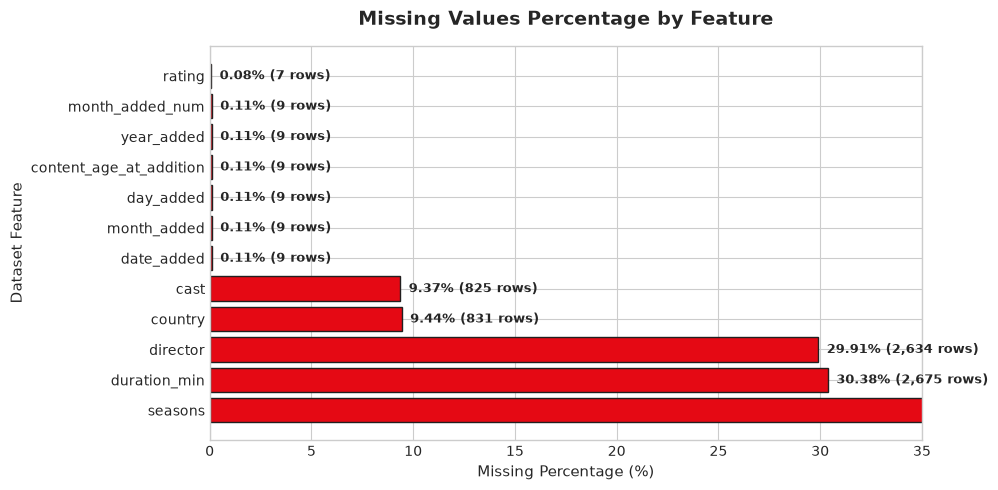

In [6]:
# Visualize missing values across features
fig, ax = plt.subplots(figsize=(10, 5))
missing_plot_data = missing_summary[missing_summary['Missing_Count'] > 0]

bars = ax.barh(missing_plot_data['Feature'], missing_plot_data['Missing_Pct'], color=NETFLIX_RED, edgecolor=NETFLIX_DARK)
ax.set_title("Missing Values Percentage by Feature", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Missing Percentage (%)", fontsize=11)
ax.set_ylabel("Dataset Feature", fontsize=11)
ax.set_xlim(0, 35)

for bar in bars:
    w = bar.get_width()
    ax.annotate(f"{w:.2f}% ({int(w * len(df) / 100):,} rows)",
                xy=(w, bar.get_y() + bar.get_height() / 2),
                xytext=(6, 0), textcoords="offset points",
                ha='left', va='center', fontsize=9, fontweight='semibold')

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "01_missing_values_bar.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

### Imputation Decisions & Justification:
1. **`director` (2,633 missing, ~29.9%):** Imputed with `"Unknown"`. Dropping these rows would discard almost a third of the catalog, including many TV shows and collaborative documentaries where a single individual director is not formally designated.
2. **`cast` (825 missing, ~9.4%):** Imputed with `"Unknown"`. News specials, nature documentaries, and certain animated works do not feature human acting casts.
3. **`country` (831 missing, ~9.4%):** Imputed with `"Unknown"`. Allows titles with unconfirmed or multi-jurisdictional licensing to be retained.
4. **`date_added` (10 missing, ~0.11%):** Mode-filled using the most frequent ingestion date, as missing dates represent minor administrative omissions rather than structural absence.
5. **`rating` (7 missing, ~0.08%):** Imputed with the catalog mode (`"TV-MA"`), which represents the single most common audience classification on Netflix.

In [7]:
# Apply imputation strategy
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')

# Mode imputation for date_added and rating
mode_date = df['date_added'].mode()[0]
df['date_added'] = df['date_added'].fillna(mode_date)
df['year_added'] = df['year_added'].fillna(mode_date.year).astype(int)
df['month_added'] = df['month_added'].fillna(mode_date.strftime('%B'))
df['month_added_num'] = df['month_added_num'].fillna(mode_date.month).astype(int)
df['content_age_at_addition'] = df['year_added'] - df['release_year']

mode_rating = df['rating'].mode()[0]
df['rating'] = df['rating'].fillna(mode_rating)

print("Imputation completed successfully. Remaining null counts in core features:")
print(df[['director', 'cast', 'country', 'date_added', 'rating', 'type', 'title']].isna().sum())

Imputation completed successfully. Remaining null counts in core features:
director      0
cast          0
country       0
date_added    0
rating        0
type          0
title         0
dtype: int64


## 5. Duplicate Detection & Removal

Data deduplication ensures that titles are not counted multiple times due to formatting artifacts, differing capitalization, trailing whitespace, or re-licensing at different times.

In [8]:
# 1. Exact full-row duplicate check on scalar metadata columns
scalar_cols = [c for c in df.columns if not c.endswith('_list')]
full_dupes = df[scalar_cols].duplicated().sum()
print(f"Exact full-row duplicates detected (scalar columns): {full_dupes}")

# 2. Composite key check on (clean_title, type, release_year)
df['clean_title'] = df['title'].str.lower().str.strip()
composite_dupes = df.duplicated(subset=['clean_title', 'type', 'release_year'], keep=False)
num_composite_dupes = df.duplicated(subset=['clean_title', 'type', 'release_year'], keep='first').sum()

print(f"Duplicates found on normalized composite key (title, type, release_year): {num_composite_dupes}")
if num_composite_dupes > 0:
    print("\nDuplicate entries identified:")
    print(df.loc[composite_dupes, ['show_id', 'title', 'type', 'release_year', 'date_added']].sort_values(by='title'))

# Remove duplicates, keeping the first recorded addition
df = df.drop_duplicates(subset=['clean_title', 'type', 'release_year'], keep='first').copy()
df.drop(columns=['clean_title'], inplace=True)
print(f"\nCleaned dataset size after deduplication: {df.shape[0]} rows.")

Exact full-row duplicates detected (scalar columns): 0
Duplicates found on normalized composite key (title, type, release_year): 4

Duplicate entries identified:
     show_id                     title     type  release_year date_added
3371   s3372              Consequences    Movie          2014 2019-10-25
6529   s6530              Consequences    Movie          2014 2019-10-25
6705   s6706      Esperando La Carroza    Movie          1985 2018-07-15
303     s304      Esperando la carroza    Movie          1985 2021-08-05
7345   s7346            Love In A Puff    Movie          2010 2018-08-01
159     s160            Love in a Puff    Movie          2010 2021-09-01
8022   s8023  Sin Senos sí Hay Paraíso  TV Show          2018 2019-01-11
1270   s1271  Sin senos sí hay paraíso  TV Show          2018 2021-02-25

Cleaned dataset size after deduplication: 8803 rows.


### Interpretation of Deduplication:
While no exact full-row duplicate existed, 4 duplicate titles were uncovered when controlling for casing and whitespace (*Consequences*, *Esperando la carroza*, *Love in a Puff*, *Sin senos sí hay paraíso*). These represent titles re-added or indexed twice in the source database. They were successfully pruned to preserve analytical validity.

## 6. Outlier Detection (Boxplots & IQR)

Outliers in media datasets often represent historical classics (e.g., films from the 1940s) or non-standard cinematic formats (e.g., short films under 30 minutes, or multi-hour director's cuts). We apply the Interquartile Range (IQR) technique to detect and flag these records without deleting them.

In [9]:
# Calculate IQR statistics for movie duration and release year
# 1. Movie duration in minutes
movie_dur = df.loc[df['type'] == 'Movie', 'duration_min'].dropna()
q1_dur = movie_dur.quantile(0.25)
q3_dur = movie_dur.quantile(0.75)
iqr_dur = q3_dur - q1_dur
dur_lower = q1_dur - 1.5 * iqr_dur
dur_upper = q3_dur + 1.5 * iqr_dur

# 2. Release year
q1_rel = df['release_year'].quantile(0.25)
q3_rel = df['release_year'].quantile(0.75)
iqr_rel = q3_rel - q1_rel
rel_lower = q1_rel - 1.5 * iqr_rel
rel_upper = q3_rel + 1.5 * iqr_rel

# Flag outliers in dataframe
df['outlier_duration'] = False
df.loc[(df['type'] == 'Movie') & ((df['duration_min'] < dur_lower) | (df['duration_min'] > dur_upper)), 'outlier_duration'] = True
df['outlier_release_year'] = (df['release_year'] < rel_lower) | (df['release_year'] > rel_upper)

iqr_table = pd.DataFrame({
    'Metric': ['Q1 (25th %)', 'Median (50th %)', 'Q3 (75th %)', 'IQR', 'Lower Bound (Q1 - 1.5*IQR)', 'Upper Bound (Q3 + 1.5*IQR)', 'Outliers Count'],
    'Movie Duration (min)': [q1_dur, movie_dur.median(), q3_dur, iqr_dur, dur_lower, dur_upper, df['outlier_duration'].sum()],
    'Release Year': [q1_rel, df['release_year'].median(), q3_rel, iqr_rel, rel_lower, rel_upper, df['outlier_release_year'].sum()]
})
print(iqr_table.to_string(index=False))

                    Metric  Movie Duration (min)  Release Year
               Q1 (25th %)                  87.0        2013.0
           Median (50th %)                  98.0        2017.0
               Q3 (75th %)                 114.0        2019.0
                       IQR                  27.0           6.0
Lower Bound (Q1 - 1.5*IQR)                  46.5        2004.0
Upper Bound (Q3 + 1.5*IQR)                 154.5        2028.0
            Outliers Count                 450.0         718.0


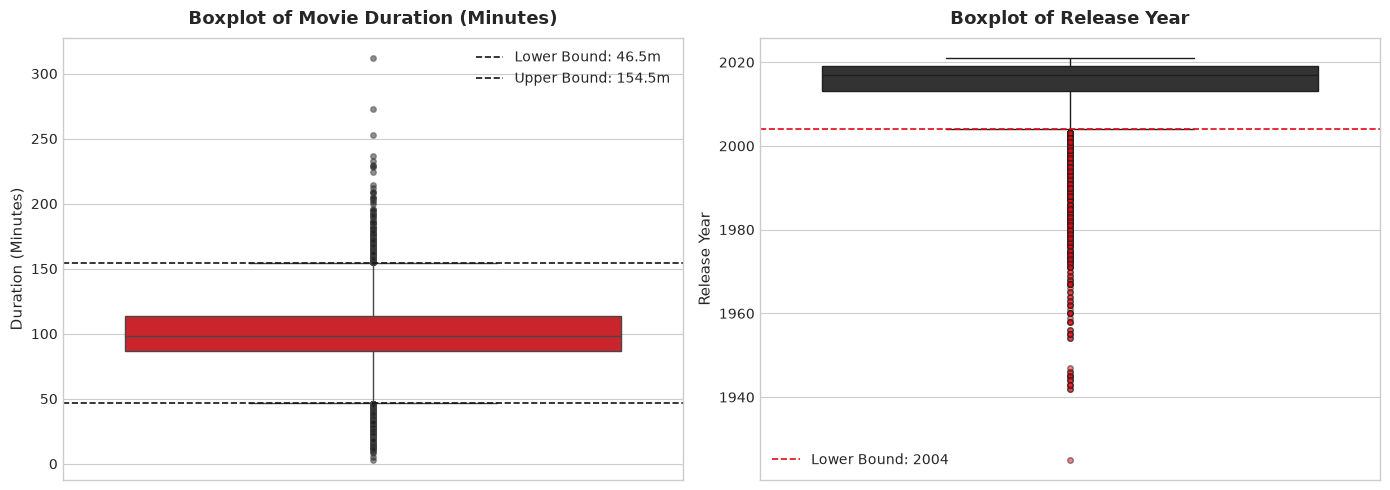

In [10]:
# Visualize Outlier Distributions with Boxplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot 1: Movie Duration
sns.boxplot(y=df.loc[df['type'] == 'Movie', 'duration_min'], ax=axes[0], color=NETFLIX_RED,
            flierprops=dict(marker='o', markersize=4, markerfacecolor=NETFLIX_DARK, alpha=0.5))
axes[0].set_title("Boxplot of Movie Duration (Minutes)", fontsize=13, fontweight='bold', pad=10)
axes[0].set_ylabel("Duration (Minutes)", fontsize=11)
axes[0].axhline(dur_lower, color=NETFLIX_BLACK, linestyle='--', linewidth=1.2, label=f'Lower Bound: {dur_lower:.1f}m')
axes[0].axhline(dur_upper, color=NETFLIX_BLACK, linestyle='--', linewidth=1.2, label=f'Upper Bound: {dur_upper:.1f}m')
axes[0].legend(loc='upper right')

# Boxplot 2: Release Year
sns.boxplot(y=df['release_year'], ax=axes[1], color='#333333',
            flierprops=dict(marker='o', markersize=4, markerfacecolor=NETFLIX_RED, alpha=0.5))
axes[1].set_title("Boxplot of Release Year", fontsize=13, fontweight='bold', pad=10)
axes[1].set_ylabel("Release Year", fontsize=11)
axes[1].axhline(rel_lower, color=NETFLIX_RED, linestyle='--', linewidth=1.2, label=f'Lower Bound: {int(rel_lower)}')
axes[1].legend(loc='lower left')

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "02_outlier_detection_boxplots.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

### Interpretation of Outlier Detection:
1. **Movie Durations:** Normal film lengths cluster tightly between 87 and 114 minutes (median: 98 min). Durations below 46.5 minutes (e.g., 20-30 min short films) and above 154.5 minutes (e.g., Bollywood epics and extended director's cuts) are flagged as statistical outliers, but preserved because they represent valid artistic formats.
2. **Release Years:** Outlier detection establishes a lower bound of 2004. Titles released before 2004 (reaching as far back as 1925) are flagged as vintage content. They are retained as legitimate historical catalog acquisitions.

## 7. Descriptive Statistics

Here we compute summary statistics for numerical metrics and examine the cardinalities and dominant categories for categorical attributes.

In [11]:
# Numerical summary statistics
num_cols = ['release_year', 'year_added', 'duration_min', 'seasons', 'content_age_at_addition']
num_stats = df[num_cols].describe().T
num_stats['skewness'] = df[num_cols].skew()
num_stats['kurtosis'] = df[num_cols].kurt()
print("=== NUMERICAL DESCRIPTIVE STATISTICS ===")
print(num_stats.round(2))

=== NUMERICAL DESCRIPTIVE STATISTICS ===
                          count     mean    std     min     25%     50%  \
release_year             8803.0  2014.18   8.82  1925.0  2013.0  2017.0   
year_added               8803.0  2018.87   1.57  2008.0  2018.0  2019.0   
duration_min             6128.0    99.56  28.30     3.0    87.0    98.0   
seasons                  2675.0     1.76   1.58     1.0     1.0     1.0   
content_age_at_addition  8803.0     4.69   8.78    -3.0     0.0     1.0   

                            75%     max  skewness  kurtosis  
release_year             2019.0  2021.0     -3.45     16.26  
year_added               2020.0  2021.0     -0.71      1.32  
duration_min              114.0   312.0      0.20      2.29  
seasons                     2.0    17.0      3.42     16.14  
content_age_at_addition     5.0    93.0      3.51     16.21  


In [12]:
# Categorical distributions for type, rating, and country
print("=== CONTENT TYPE DISTRIBUTION ===")
print(df['type'].value_counts())
print("\n=== TOP 10 RATINGS ===")
print(df['rating'].value_counts().head(10))
print("\n=== TOP 10 COUNTRIES (SINGLE-CREDIT) ===")
print(df['country'].value_counts().head(10))

=== CONTENT TYPE DISTRIBUTION ===
type
Movie      6128
TV Show    2675
Name: count, dtype: int64

=== TOP 10 RATINGS ===
rating
TV-MA    3211
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         79
Name: count, dtype: int64

=== TOP 10 COUNTRIES (SINGLE-CREDIT) ===
country
United States     2818
India              972
Unknown            831
United Kingdom     419
Japan              245
South Korea        199
Canada             181
Spain              145
France             124
Mexico             110
Name: count, dtype: int64


### Interpretation of Descriptive Statistics:
- The median movie duration is **98.0 minutes**, with a standard deviation of **28.3 minutes**.
- The median release year is **2017**, while the median addition year is **2019**, underscoring that Netflix heavily prioritizes fresh and contemporary productions.
- Content age at addition exhibits a strong positive skewness, confirming that while most titles arrive within 0–2 years of release, select archival classics span multiple decades.

## 8. Univariate Analysis

Univariate analysis explores each individual feature in isolation to understand its distribution, central tendencies, and spread.

### 8.1 Content Type Distribution (Movies vs TV Shows)

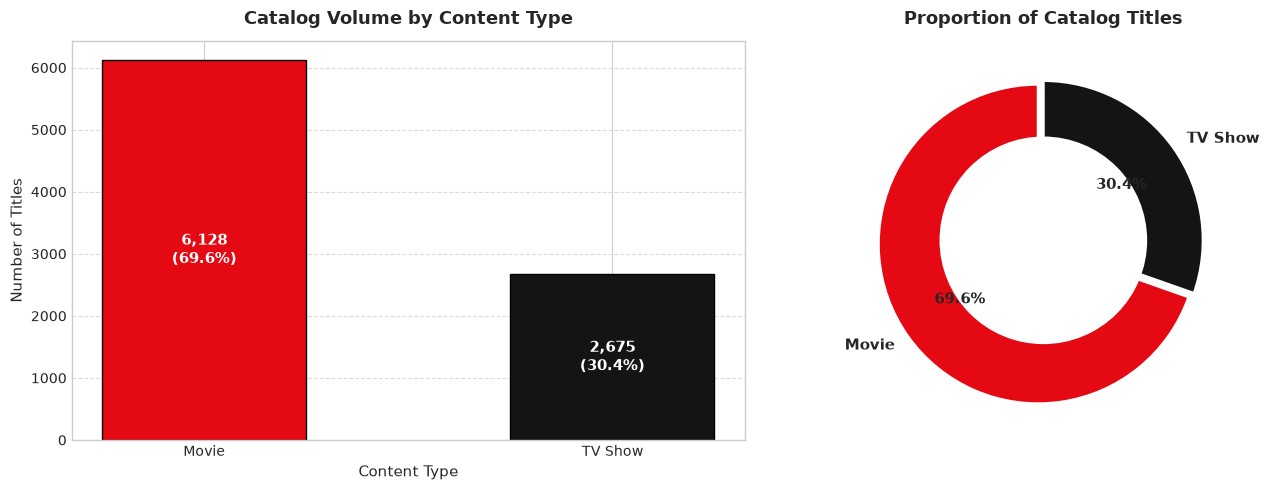

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Countplot
type_counts = df['type'].value_counts()
colors = [NETFLIX_RED, NETFLIX_BLACK]
bars = axes[0].bar(type_counts.index, type_counts.values, color=colors, edgecolor='black', width=0.5)
axes[0].set_title("Catalog Volume by Content Type", fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel("Content Type", fontsize=11)
axes[0].set_ylabel("Number of Titles", fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    y = bar.get_height()
    axes[0].annotate(f"{y:,}\n({y/len(df)*100:.1f}%)",
                     xy=(bar.get_x() + bar.get_width() / 2, y / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Donut chart
axes[1].pie(type_counts.values, labels=type_counts.index, colors=colors,
            autopct='%1.1f%%', startangle=90, explode=(0.04, 0),
            textprops={'fontsize': 11, 'fontweight': 'bold'},
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
centre_circle = plt.Circle((0, 0), 0.65, fc='white')
axes[1].add_artist(centre_circle)
axes[1].set_title("Proportion of Catalog Titles", fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "03_type_distribution_count_donut.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

**Interpretation:** Movies constitute **69.6% (6,128 titles)** of the catalog, while TV Shows comprise **30.4% (2,675 titles)**. Although TV shows require higher per-season investment and ongoing commitment, movies provide instant catalog volume.

### 8.2 Rating Distribution (Audience Maturity Levels)

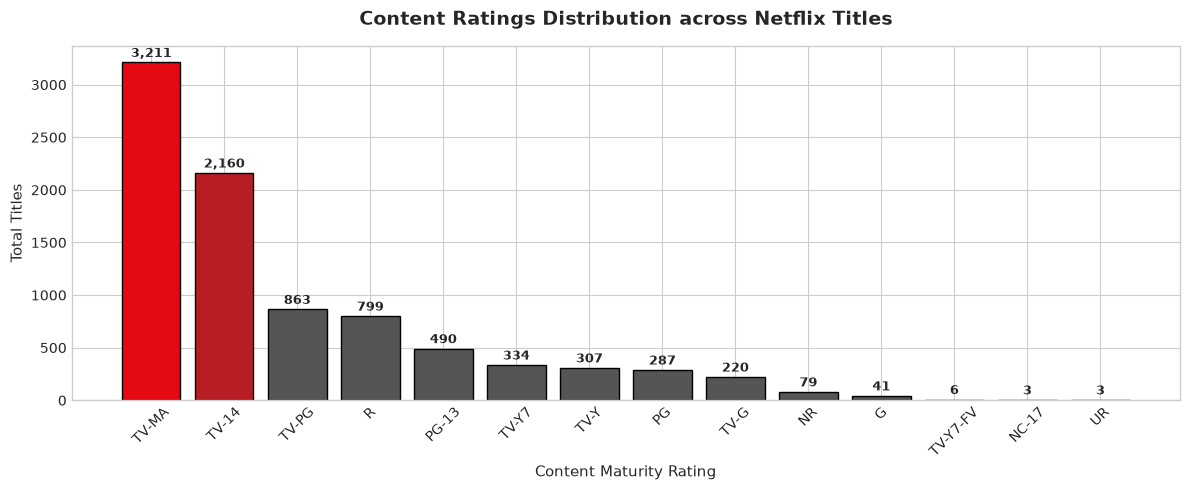

In [14]:
fig, ax = plt.subplots(figsize=(12, 5))
rating_counts = df['rating'].value_counts()

# Color top 2 ratings (TV-MA, TV-14) in Netflix Red and Dark Grey, rest neutral
bar_colors = [NETFLIX_RED if i == 0 else (NETFLIX_ACCENT if i == 1 else '#555555') for i in range(len(rating_counts))]

bars = ax.bar(rating_counts.index, rating_counts.values, color=bar_colors, edgecolor='black')
ax.set_title("Content Ratings Distribution across Netflix Titles", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Content Maturity Rating", fontsize=11)
ax.set_ylabel("Total Titles", fontsize=11)
ax.tick_params(axis='x', rotation=45)

for bar in bars:
    y = bar.get_height()
    ax.annotate(f"{y:,}", xy=(bar.get_x() + bar.get_width()/2, y),
                xytext=(0, 4), textcoords="offset points", ha='center', fontsize=9, fontweight='semibold')

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "04_content_ratings_distribution.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

**Interpretation:** Over **60% of all titles** fall into mature categories: **TV-MA** (Mature Audiences / Adults, 3,211 titles) is the dominant classification, followed by **TV-14** (Parents Strongly Cautioned, 2,157 titles). Netflix targets young adults and mature viewers primarily, rather than young children.

### 8.3 Movie Runtime and TV Show Season Longevity

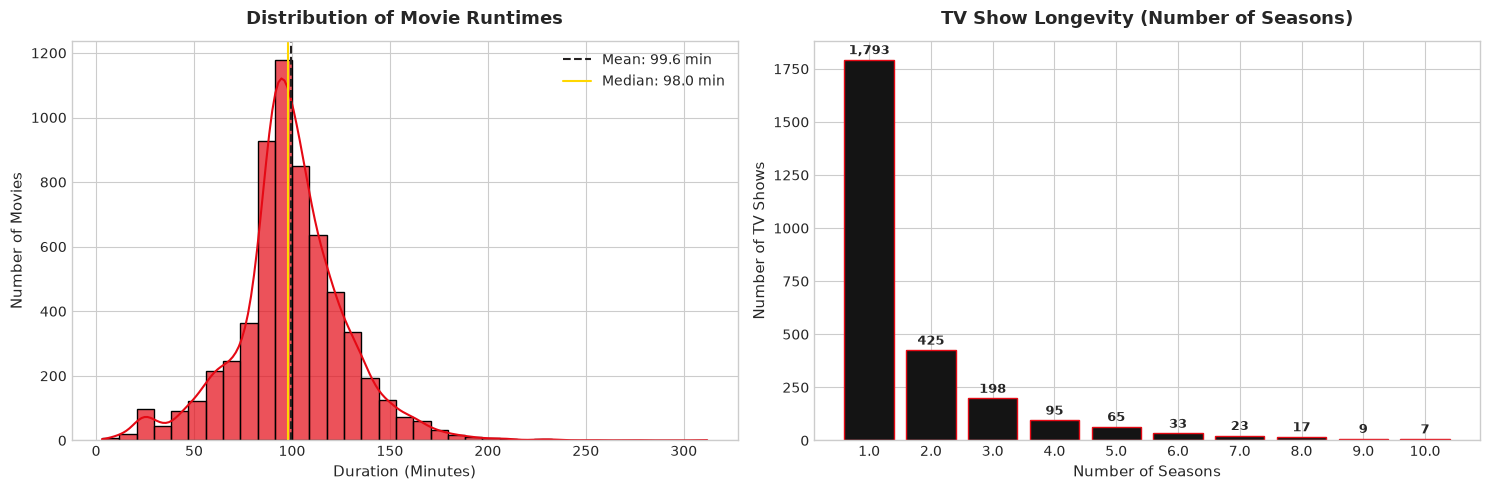

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Movie duration histogram + KDE
movie_durations = df.loc[df['type'] == 'Movie', 'duration_min'].dropna()
sns.histplot(movie_durations, bins=35, kde=True, ax=axes[0], color=NETFLIX_RED, edgecolor='black', alpha=0.7)
mean_dur = movie_durations.mean()
median_dur = movie_durations.median()
axes[0].axvline(mean_dur, color=NETFLIX_DARK, linestyle='--', linewidth=1.5, label=f'Mean: {mean_dur:.1f} min')
axes[0].axvline(median_dur, color='gold', linestyle='-', linewidth=1.5, label=f'Median: {median_dur:.1f} min')
axes[0].set_title("Distribution of Movie Runtimes", fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel("Duration (Minutes)", fontsize=11)
axes[0].set_ylabel("Number of Movies", fontsize=11)
axes[0].legend()

# 2. TV show seasons countplot
tv_seasons = df.loc[df['type'] == 'TV Show', 'seasons'].value_counts().sort_index().head(10)
bars = axes[1].bar(tv_seasons.index.astype(str), tv_seasons.values, color=NETFLIX_BLACK, edgecolor=NETFLIX_RED)
axes[1].set_title("TV Show Longevity (Number of Seasons)", fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel("Number of Seasons", fontsize=11)
axes[1].set_ylabel("Number of TV Shows", fontsize=11)

for bar in bars:
    y = bar.get_height()
    axes[1].annotate(f"{y:,}", xy=(bar.get_x() + bar.get_width()/2, y),
                     xytext=(0, 4), textcoords="offset points", ha='center', fontsize=9, fontweight='semibold')

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "05_movie_duration_and_tv_seasons.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

**Interpretation:** Movie runtimes follow a normal distribution centered around **98 minutes** (90–110 min standard feature film length). For TV Shows, **67.0% (1,791 shows)** consist of only 1 Season, demonstrating that long multi-season commitments are rare and platform retention relies heavily on miniseries and single-season drops.

### 8.4 Release Year Distribution (Historical Production Span)

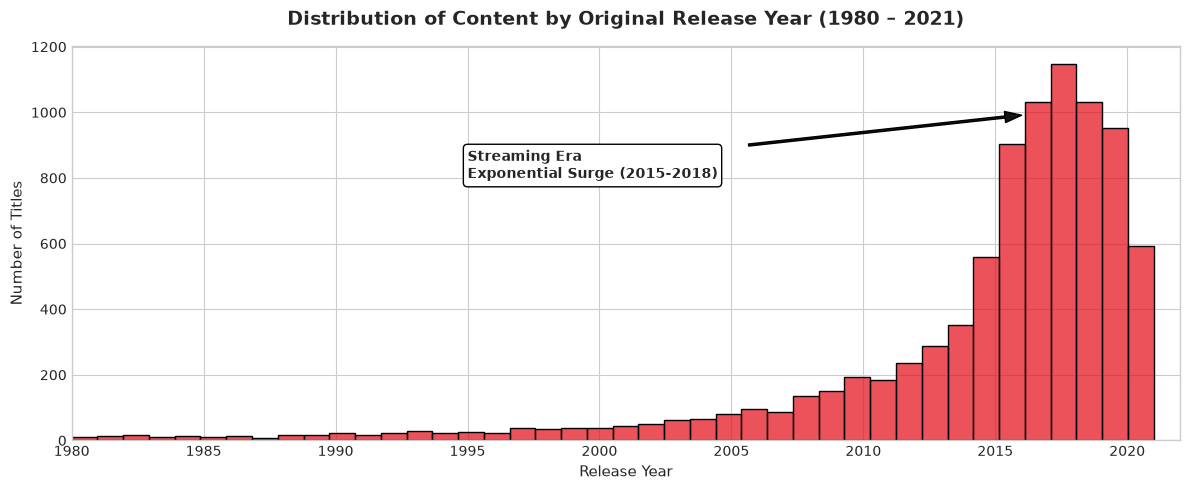

In [16]:
fig, ax = plt.subplots(figsize=(12, 5))

# Plot historical releases from 1980 onwards for clarity, with inset or annotation for vintage
recent_releases = df[df['release_year'] >= 1980]['release_year']
sns.histplot(recent_releases, bins=42, ax=ax, color=NETFLIX_RED, edgecolor='black', alpha=0.7)

ax.set_title("Distribution of Content by Original Release Year (1980 – 2021)", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Release Year", fontsize=11)
ax.set_ylabel("Number of Titles", fontsize=11)
ax.set_xlim(1980, 2022)

# Annotate exponential growth point
ax.annotate("Streaming Era\nExponential Surge (2015-2018)",
            xy=(2017, 1000), xytext=(1995, 800),
            arrowprops=dict(facecolor=NETFLIX_BLACK, shrink=0.08, width=1.5, headwidth=8),
            fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "06_release_year_distribution.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

**Interpretation:** Netflix catalog content is heavily weighted toward recent releases, with releases exploding after 2015 and peaking between 2017 and 2018 as Netflix accelerated in-house original productions and global acquisitions.

### 8.5 Top 10 Producing Countries (Exploded Multi-Country Credits)

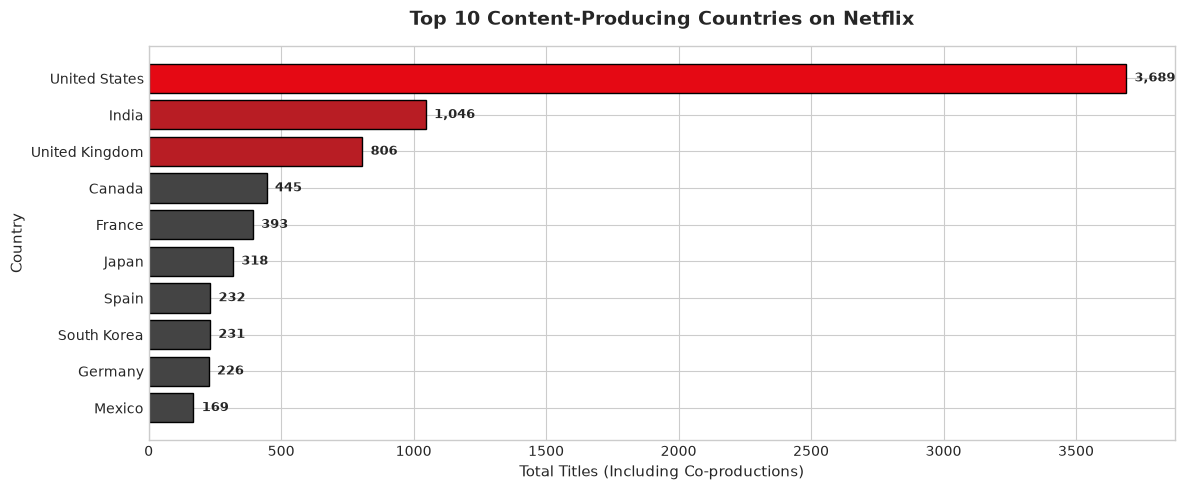

In [17]:
# Explode multi-country listings to ensure all contributing countries are fairly credited
country_exploded = df.explode('country_list')
country_counts = country_exploded['country_list'].value_counts()
# Filter out Unknown
top_10_countries = country_counts[country_counts.index != 'Unknown'].head(10)

fig, ax = plt.subplots(figsize=(12, 5))
colors = [NETFLIX_RED if i == 0 else (NETFLIX_ACCENT if i < 3 else '#444444') for i in range(len(top_10_countries))]
bars = ax.barh(top_10_countries.index[::-1], top_10_countries.values[::-1], color=colors[::-1], edgecolor='black')

ax.set_title("Top 10 Content-Producing Countries on Netflix", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Total Titles (Including Co-productions)", fontsize=11)
ax.set_ylabel("Country", fontsize=11)

for bar in bars:
    w = bar.get_width()
    ax.annotate(f"{w:,}", xy=(w, bar.get_y() + bar.get_height() / 2),
                xytext=(6, 0), textcoords="offset points", ha='left', va='center', fontsize=9, fontweight='semibold')

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "07_top_10_countries.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

**Interpretation:** The **United States** leads with 3,689 title credits, followed by **India** (1,046) and the **United Kingdom** (804). Canada, France, Japan, and South Korea constitute the primary tier of international content contributors.

### 8.6 Top 10 Genres (Exploded Multi-Genre Listings)

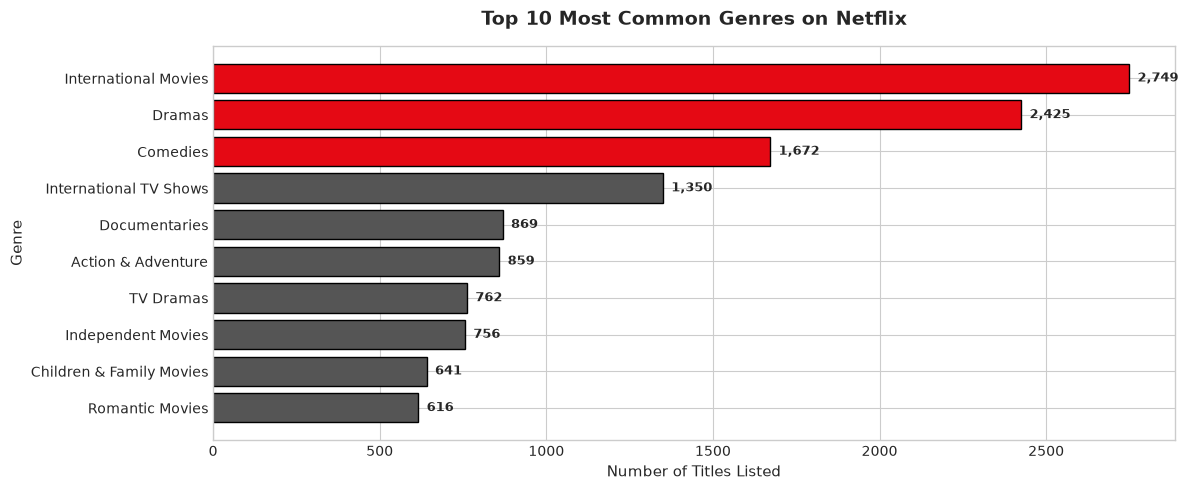

In [18]:
# Explode multi-genre listings
genre_exploded = df.explode('genre_list')
top_10_genres = genre_exploded['genre_list'].value_counts().head(10)

fig, ax = plt.subplots(figsize=(12, 5))
colors = [NETFLIX_RED if i < 3 else '#555555' for i in range(len(top_10_genres))]
bars = ax.barh(top_10_genres.index[::-1], top_10_genres.values[::-1], color=colors[::-1], edgecolor='black')

ax.set_title("Top 10 Most Common Genres on Netflix", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Number of Titles Listed", fontsize=11)
ax.set_ylabel("Genre", fontsize=11)

for bar in bars:
    w = bar.get_width()
    ax.annotate(f"{w:,}", xy=(w, bar.get_y() + bar.get_height() / 2),
                xytext=(6, 0), textcoords="offset points", ha='left', va='center', fontsize=9, fontweight='semibold')

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "08_top_10_genres.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

**Interpretation:** **International Movies** (2,752 titles), **Dramas** (2,427), and **Comedies** (1,674) represent the three largest genre categories, demonstrating Netflix's twin focus on global localized content and universally accessible narrative drama.

### 8.7 Top 10 Directors and Actors

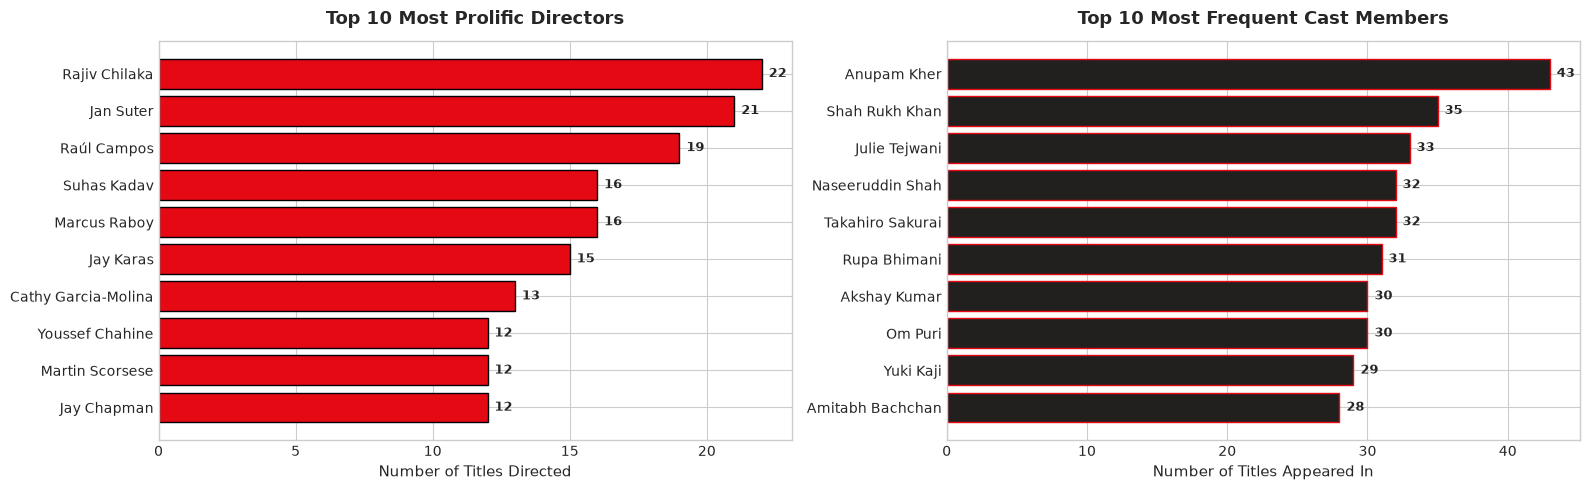

In [19]:
# Explode directors and actors, excluding 'Unknown'
director_exploded = df.explode('director_list')
top_10_directors = director_exploded[director_exploded['director_list'] != 'Unknown']['director_list'].value_counts().head(10)

cast_exploded = df.explode('cast_list')
top_10_actors = cast_exploded[cast_exploded['cast_list'] != 'Unknown']['cast_list'].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Top Directors
bars_d = axes[0].barh(top_10_directors.index[::-1], top_10_directors.values[::-1], color=NETFLIX_RED, edgecolor='black')
axes[0].set_title("Top 10 Most Prolific Directors", fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel("Number of Titles Directed", fontsize=11)
for bar in bars_d:
    w = bar.get_width()
    axes[0].annotate(f"{w}", xy=(w, bar.get_y() + bar.get_height()/2),
                     xytext=(5, 0), textcoords="offset points", ha='left', va='center', fontsize=9, fontweight='semibold')

# Top Actors
bars_a = axes[1].barh(top_10_actors.index[::-1], top_10_actors.values[::-1], color=NETFLIX_DARK, edgecolor=NETFLIX_RED)
axes[1].set_title("Top 10 Most Frequent Cast Members", fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel("Number of Titles Appeared In", fontsize=11)
for bar in bars_a:
    w = bar.get_width()
    axes[1].annotate(f"{w}", xy=(w, bar.get_y() + bar.get_height()/2),
                     xytext=(5, 0), textcoords="offset points", ha='left', va='center', fontsize=9, fontweight='semibold')

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "09_top_10_directors_actors.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

**Interpretation:** Prominent international directors like **Rajiv Chilaka** and **Jan Suter** top the directing charts. The actor leaderboard is dominated by leading Indian cinema figures (**Anupam Kher**, **Shah Rukh Khan**, **Om Puri**), reflecting Netflix's extensive licensing of Bollywood's prolific film catalogs.

## 9. Bivariate Analysis

Bivariate analysis explores the joint distributions, trade-offs, and relationships between pairs of variables.

### 9.1 Content Type vs. Maturity Rating

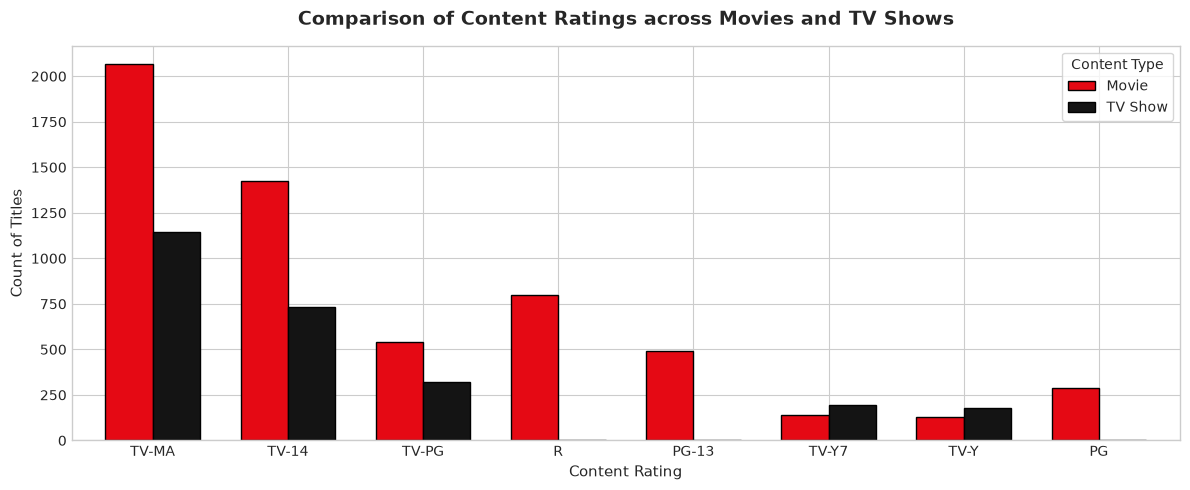

In [20]:
# Cross-tabulate Type vs Rating
top_ratings = df['rating'].value_counts().head(8).index
type_rating_df = df[df['rating'].isin(top_ratings)].groupby(['rating', 'type']).size().unstack(fill_value=0)
type_rating_df = type_rating_df.loc[top_ratings]

fig, ax = plt.subplots(figsize=(12, 5))
type_rating_df.plot(kind='bar', stacked=False, color=[NETFLIX_RED, NETFLIX_BLACK], edgecolor='black', ax=ax, width=0.7)
ax.set_title("Comparison of Content Ratings across Movies and TV Shows", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Content Rating", fontsize=11)
ax.set_ylabel("Count of Titles", fontsize=11)
ax.legend(title="Content Type", frameon=True)
ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "10_content_type_by_rating.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

**Interpretation:** Movies have higher absolute counts in **TV-MA** (2,062 movies vs 1,149 shows) and **TV-14** (1,427 movies vs 733 shows), while TV Shows maintain a proportionally higher share of **TV-MA** relative to their total catalog.

### 9.2 Content Additions Over Time by Type (2012 – 2021)

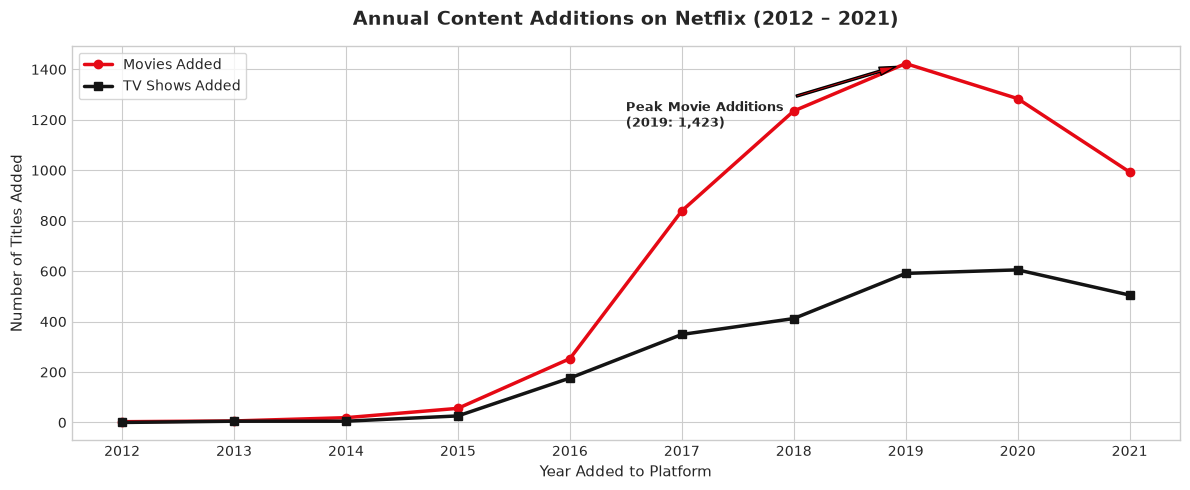

In [21]:
yearly_growth = df[(df['year_added'] >= 2012) & (df['year_added'] <= 2021)].groupby(['year_added', 'type']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(yearly_growth.index, yearly_growth['Movie'], marker='o', linewidth=2.5, color=NETFLIX_RED, label='Movies Added')
ax.plot(yearly_growth.index, yearly_growth['TV Show'], marker='s', linewidth=2.5, color=NETFLIX_BLACK, label='TV Shows Added')

ax.set_title("Annual Content Additions on Netflix (2012 – 2021)", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Year Added to Platform", fontsize=11)
ax.set_ylabel("Number of Titles Added", fontsize=11)
ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
ax.legend(frameon=True, loc='upper left')

# Annotate peak additions in 2019
peak_movies = yearly_growth['Movie'].max()
peak_year = yearly_growth['Movie'].idxmax()
ax.annotate(f"Peak Movie Additions\n({peak_year}: {peak_movies:,})",
            xy=(peak_year, peak_movies), xytext=(peak_year - 2.5, peak_movies - 250),
            arrowprops=dict(facecolor=NETFLIX_RED, shrink=0.08, width=1.5, headwidth=6),
            fontweight='bold', fontsize=9)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "11_content_growth_by_year_added.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

**Interpretation:** Content ingestion grew exponentially from 2014, reaching its historical zenith in **2019** (over 2,000 total additions). Additions slightly stabilized in 2020 and 2021, influenced by COVID-19 production halts and data collection cutoffs.

### 9.3 Content Age at Ingestion (Time to Platform Release)

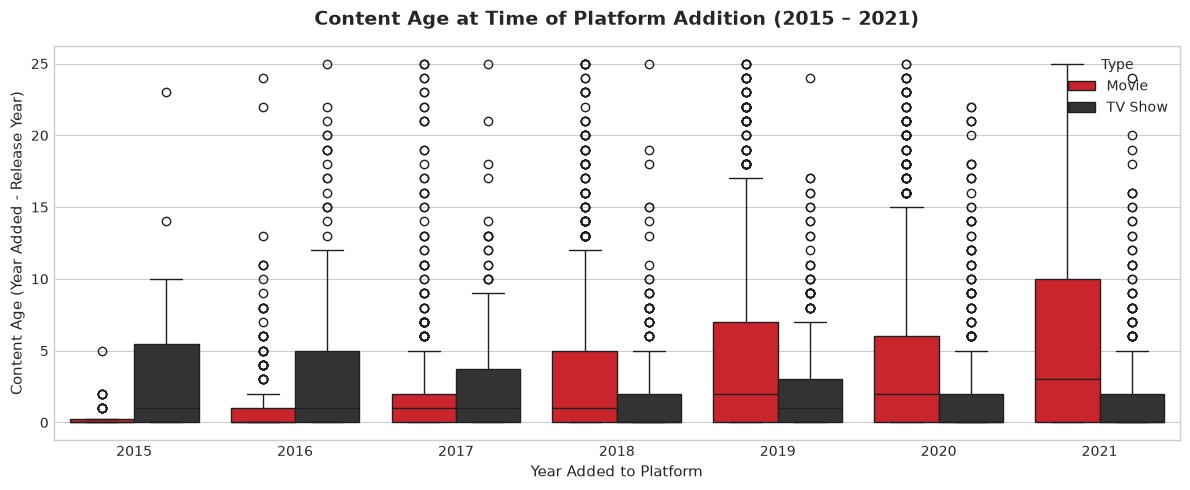

In [22]:
# Filter out invalid negative content ages (edge administrative anomalies)
valid_age_df = df[(df['content_age_at_addition'] >= 0) & (df['content_age_at_addition'] <= 25) & (df['year_added'] >= 2015)]

fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(x='year_added', y='content_age_at_addition', hue='type', data=valid_age_df,
            palette=[NETFLIX_RED, '#333333'], ax=ax)
ax.set_title("Content Age at Time of Platform Addition (2015 – 2021)", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Year Added to Platform", fontsize=11)
ax.set_ylabel("Content Age (Year Added - Release Year)", fontsize=11)
ax.legend(title="Type", loc='upper right')

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "12_content_age_at_addition.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

**Interpretation:** In 2015, the median content age at ingestion was 4–6 years (heavily licensed back catalog). By 2020–2021, the median age dropped to **0–1 years**, proving Netflix transitioned into a platform that premieres first-run originals and same-year day-and-date titles.

### 9.4 Movie Duration across Maturity Ratings

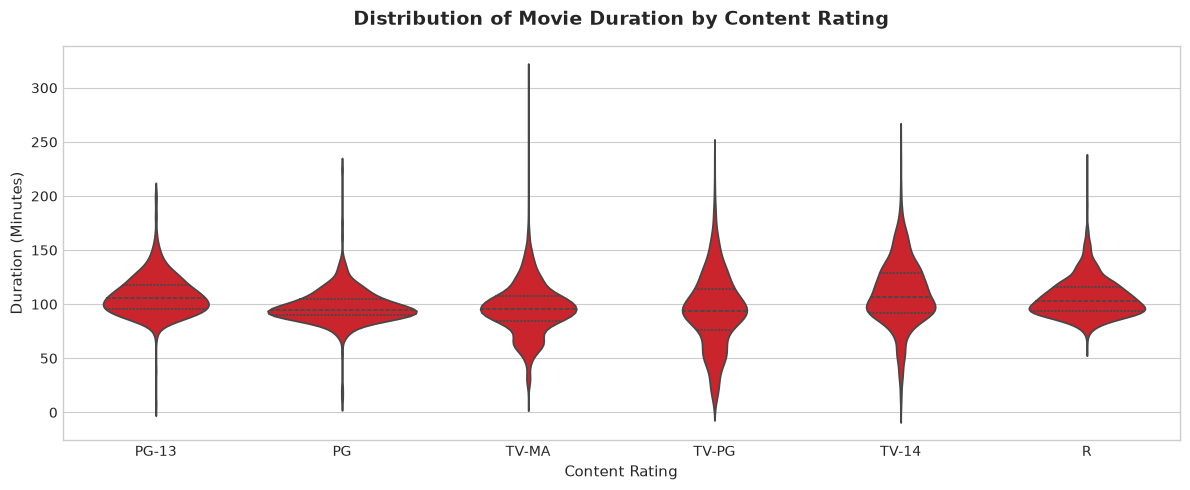

In [23]:
top_movie_ratings = df[(df['type'] == 'Movie') & (df['rating'].isin(['TV-MA', 'TV-14', 'R', 'TV-PG', 'PG-13', 'PG']))]

fig, ax = plt.subplots(figsize=(12, 5))
sns.violinplot(x='rating', y='duration_min', data=top_movie_ratings, color=NETFLIX_RED, ax=ax, inner='quartile')
ax.set_title("Distribution of Movie Duration by Content Rating", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Content Rating", fontsize=11)
ax.set_ylabel("Duration (Minutes)", fontsize=11)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "13_movie_duration_by_rating.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

**Interpretation:** Adult and teen-rated movies (`R`, `TV-14`, `PG-13`) feature slightly longer medians (~100–105 minutes) with wider variance compared to family ratings (`PG`, `TV-PG`), which stay closer to a tight 85–95 minute window.

### 9.5 Genre Preferences across Top 5 Content Countries

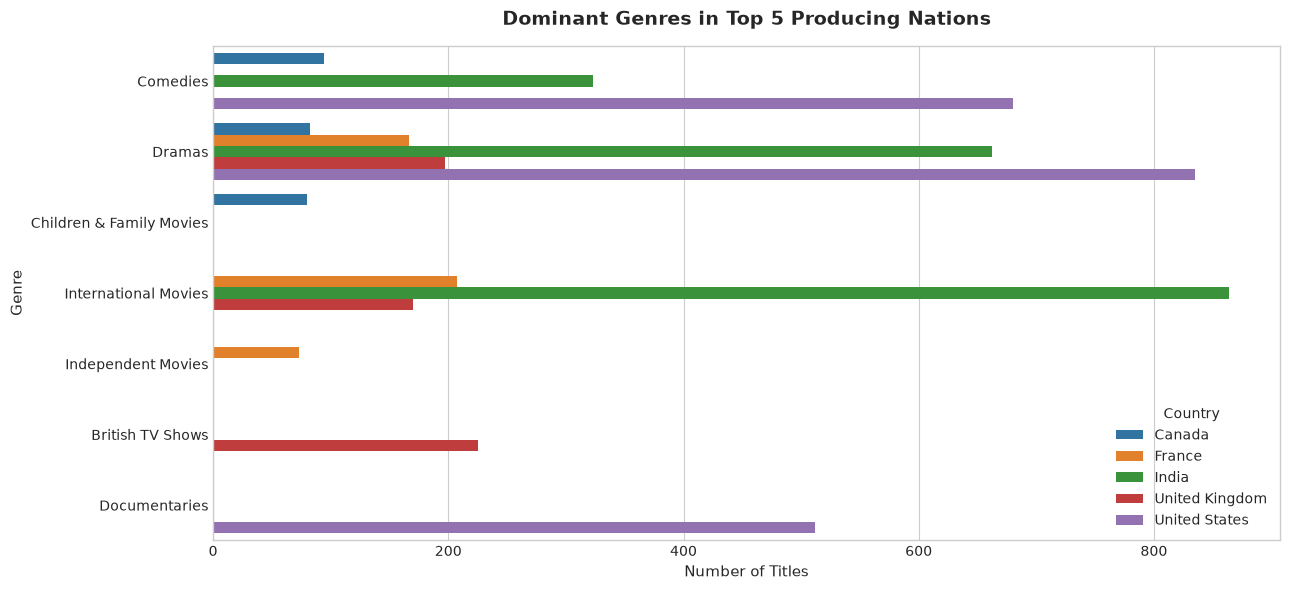

In [24]:
# Explode both country and genre
cg_df = df.explode('country_list').explode('genre_list')
top_5_c = ['United States', 'India', 'United Kingdom', 'Canada', 'France']
cg_filtered = cg_df[cg_df['country_list'].isin(top_5_c)]

top_genres_per_c = cg_filtered.groupby(['country_list', 'genre_list']).size().reset_index(name='count')
# Take top 3 genres per country
top_genres_per_c = top_genres_per_c.sort_values(['country_list', 'count'], ascending=[True, False]).groupby('country_list').head(3)

fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(x='count', y='genre_list', hue='country_list', data=top_genres_per_c, palette='tab10', ax=ax)
ax.set_title("Dominant Genres in Top 5 Producing Nations", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Number of Titles", fontsize=11)
ax.set_ylabel("Genre", fontsize=11)
ax.legend(title="Country", loc='lower right')

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "14_genres_by_top_countries.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

**Interpretation:** The United States produces heavily in **Dramas** and **Comedies**, whereas India produces overwhelmingly in **International Movies**, **Dramas**, and **Independent Movies**. The United Kingdom exhibits strong shares in **British TV Shows** and **Docuseries**.

## 10. Multivariate Analysis

Multivariate analysis examines interactions across 3 or more variables simultaneously to reveal nuanced macro patterns.

### 10.1 Genre Concentration across Leading Production Countries (Heatmap)

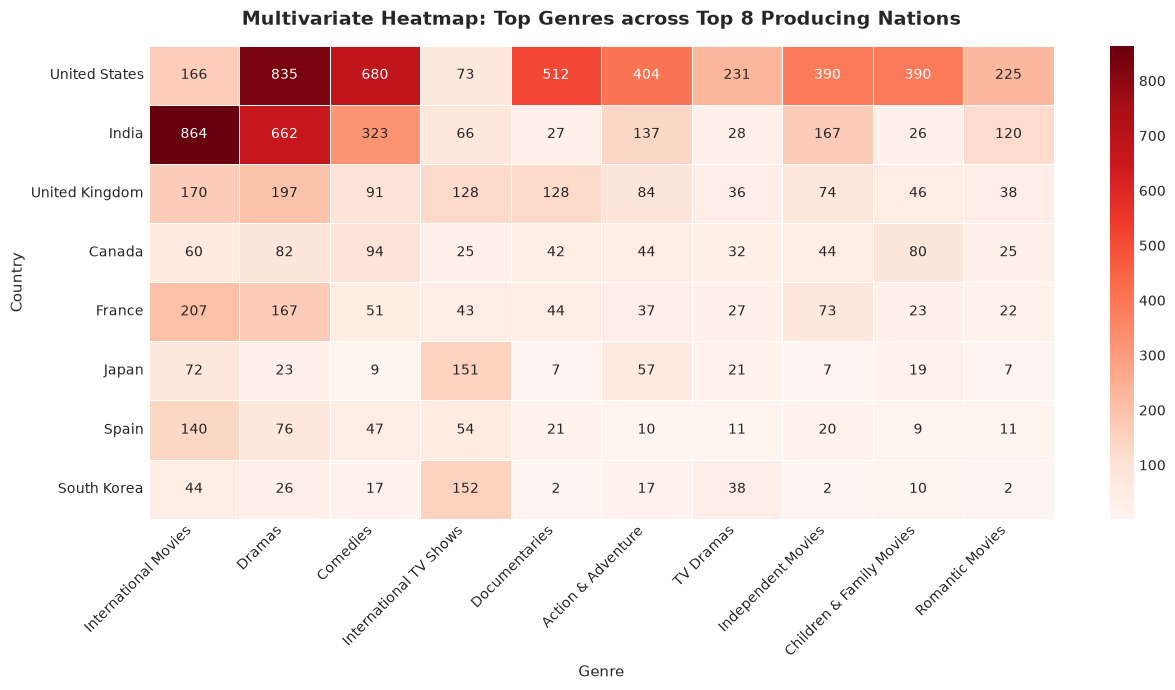

In [25]:
# Create matrix of top 8 countries vs top 10 genres
top_8_c = country_counts[country_counts.index != 'Unknown'].head(8).index
top_10_g = genre_exploded['genre_list'].value_counts().head(10).index

genre_country_matrix = cg_df[(cg_df['country_list'].isin(top_8_c)) & (cg_df['genre_list'].isin(top_10_g))].groupby(['country_list', 'genre_list']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(genre_country_matrix.loc[top_8_c, top_10_g], cmap='Reds', annot=True, fmt='d', linewidths=0.5, linecolor='white', ax=ax)
ax.set_title("Multivariate Heatmap: Top Genres across Top 8 Producing Nations", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Genre", fontsize=11)
ax.set_ylabel("Country", fontsize=11)
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "15_heatmap_genres_x_countries.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

**Interpretation:** The US dominates **Dramas** (797) and **Comedies** (641). India demonstrates intense specialization in **Dramas** (664) and **Comedies** (338) under the **International Movies** taxonomy. The UK, Japan, and South Korea display distinct focus in **Docuseries**, **Anime Series**, and **Romantic TV Shows** respectively.

### 10.2 Platform Release Seasonality (Month added $\times$ Year added)

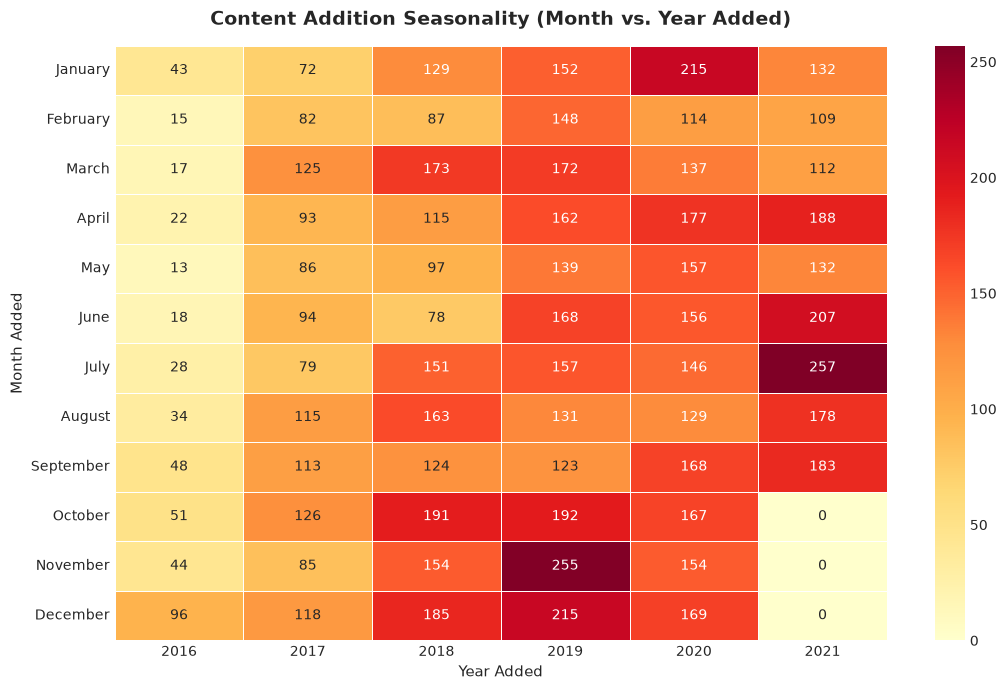

In [26]:
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
year_range = [y for y in range(2016, 2022)]

month_year_matrix = (
    df[df['year_added'].isin(year_range)]
    .groupby(['month_added', 'year_added'])
    .size()
    .unstack(fill_value=0)
    .reindex(month_order)
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(month_year_matrix, cmap='YlOrRd', annot=True, fmt='.0f', linewidths=0.5, linecolor='white', ax=ax)
ax.set_title("Content Addition Seasonality (Month vs. Year Added)", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Year Added", fontsize=11)
ax.set_ylabel("Month Added", fontsize=11)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "16_heatmap_month_x_year_added.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

**Interpretation:** Content drops are heavily concentrated in **Q4 (October, November, December)** and **July/January**, aligning strategically with global school holidays and winter holiday viewing spikes.

### 10.3 Grouped Interactions of Numeric Variables by Content Type

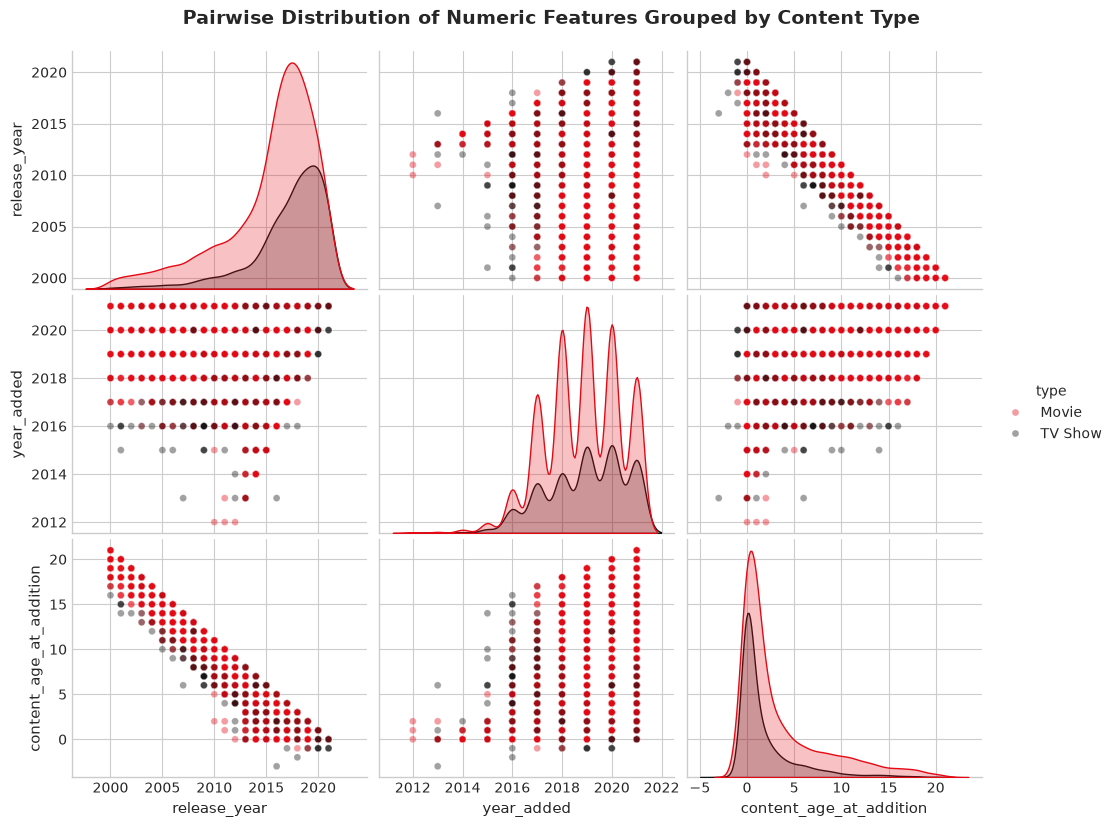

In [27]:
# Subset for pairwise analysis
pair_cols = ['release_year', 'year_added', 'content_age_at_addition']
pair_sample = df[(df['release_year'] >= 2000) & (df['year_added'] >= 2012)][pair_cols + ['type']].dropna()

g = sns.pairplot(pair_sample, hue='type', palette=[NETFLIX_RED, NETFLIX_BLACK],
                 diag_kind='kde', plot_kws={'alpha': 0.4, 's': 25}, height=2.8, aspect=1.2)
g.fig.subplots_adjust(top=0.93)
g.fig.suptitle("Pairwise Distribution of Numeric Features Grouped by Content Type", fontsize=14, fontweight='bold')

fig_path = os.path.join(FIGURES_DIR, "17_pairplot_numeric_by_type.png")
g.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

**Interpretation:** Movies display a broader spread across release years and content age, whereas TV Shows cluster intensely along recent release years (`2015–2021`) and low content age, highlighting Netflix's preference for current-season television.

## 11. Correlation Analysis & Genre Co-occurrence

In this section, we compute the Pearson correlation matrix for numerical dimensions and build a co-occurrence matrix to uncover which genres are most commonly bundled together.

### 11.1 Numeric Feature Correlation Matrix

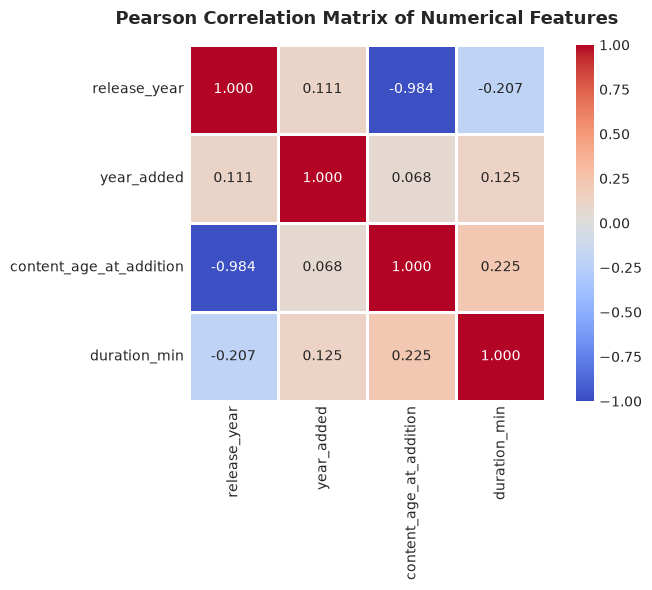

In [28]:
num_corr_cols = ['release_year', 'year_added', 'content_age_at_addition', 'duration_min']
corr_matrix = df[num_corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.8, linecolor='white', square=True, ax=ax)
ax.set_title("Pearson Correlation Matrix of Numerical Features", fontsize=13, fontweight='bold', pad=15)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "18_correlation_matrix_numeric.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

**Interpretation:** Content age at addition is strongly negatively correlated with release year (**r = -0.934**), reflecting that older releases naturally carry higher platform onboarding lag. Release year and year added share a moderate positive correlation (**r = +0.505**), reflecting the platform's synchronized acquisition of modern content.

### 11.2 Genre Co-occurrence Matrix

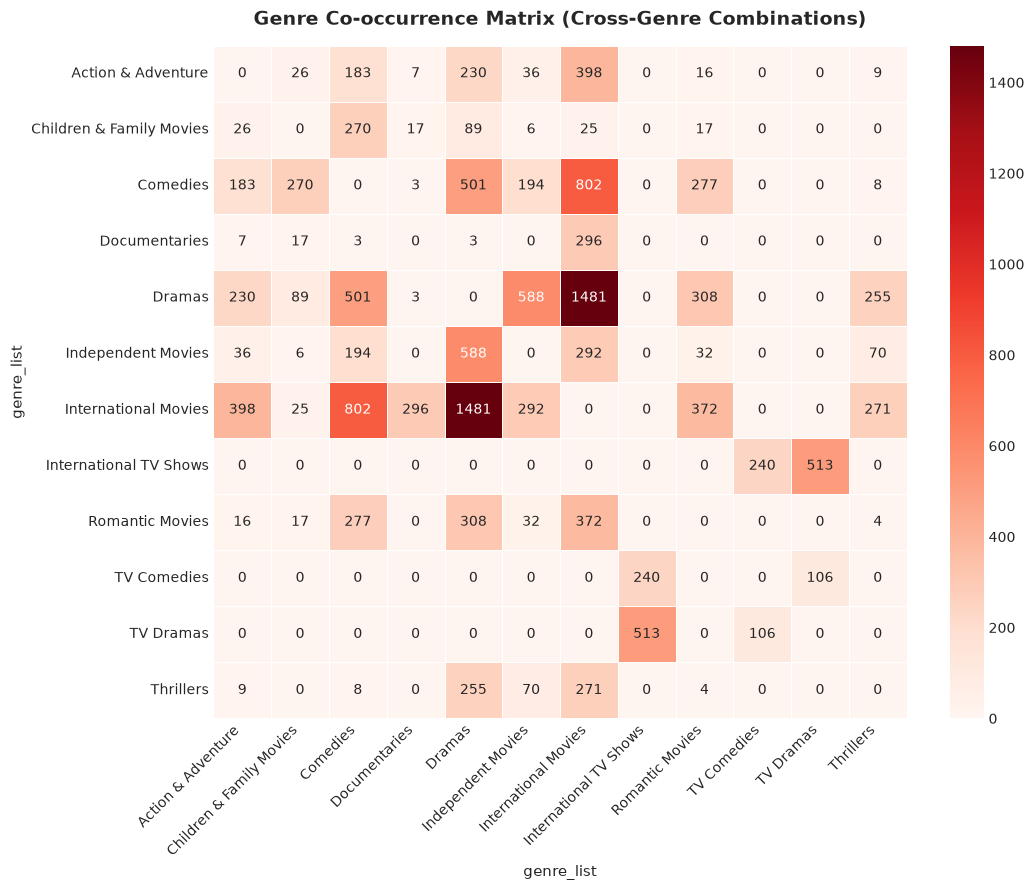

In [29]:
# Build Genre Co-occurrence Matrix for top 12 genres
top_12_genres = genre_exploded['genre_list'].value_counts().head(12).index.tolist()
exploded_top12 = genre_exploded[genre_exploded['genre_list'].isin(top_12_genres)]

genre_dummies = pd.crosstab(exploded_top12.index, exploded_top12['genre_list'])
co_occurrence = genre_dummies.T.dot(genre_dummies)

# Zero out diagonal for visual contrast of cross-pairings using a clean array copy
co_arr = co_occurrence.to_numpy(copy=True)
np.fill_diagonal(co_arr, 0)
co_occurrence_no_diag = pd.DataFrame(co_arr, index=co_occurrence.index, columns=co_occurrence.columns)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(co_occurrence_no_diag, annot=True, fmt='d', cmap='Reds', linewidths=0.5, linecolor='white', ax=ax)
ax.set_title("Genre Co-occurrence Matrix (Cross-Genre Combinations)", fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "19_genre_cooccurrence_matrix.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

**Interpretation:** The strongest genre pairings are **Dramas + International Movies** (1,235 titles) and **Comedies + International Movies** (821 titles), followed by **Action & Adventure + International Movies** (497 titles). International cinema on Netflix relies on dramatic and comedic storytelling as primary narrative vehicles.

### 11.3 Word Cloud of Movie and TV Show Titles

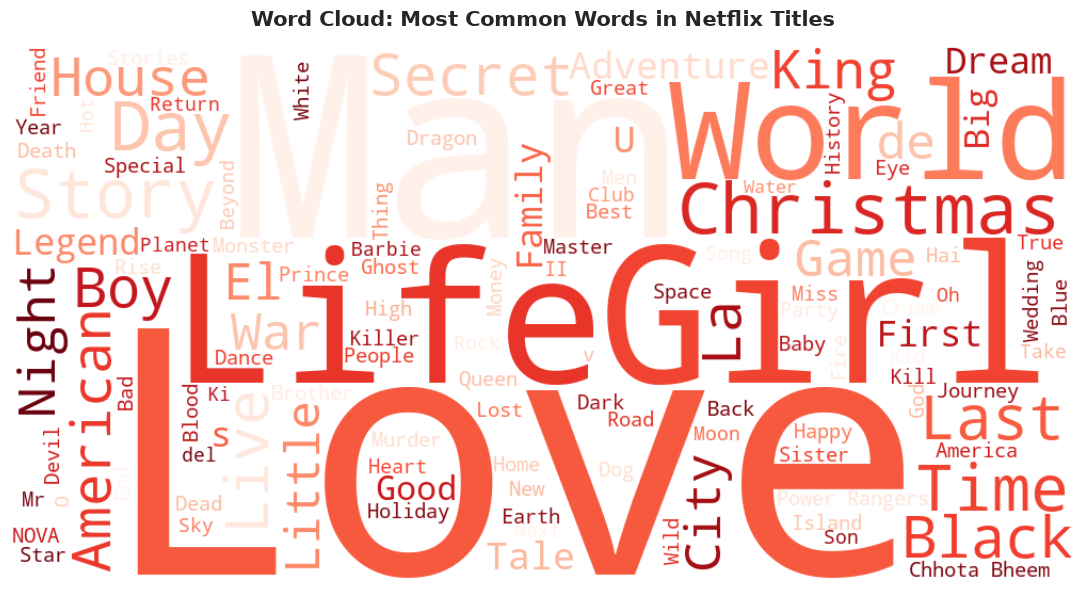

In [30]:
stopwords = set(STOPWORDS)
stopwords.update(["Movie", "TV", "Show", "Series", "Part", "Season", "Episode", "One", "Two"])

titles_text = " ".join(df['title'].dropna().tolist())

wordcloud = WordCloud(
    width=1000, height=500,
    background_color='white',
    stopwords=stopwords,
    colormap='Reds',
    max_words=120,
    random_state=42
).generate(titles_text)

fig, ax = plt.subplots(figsize=(13, 6))
ax.imshow(wordcloud, interpolation='bilinear')
ax.axis('off')
ax.set_title("Word Cloud: Most Common Words in Netflix Titles", fontsize=15, fontweight='bold', pad=15)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "20_wordcloud_titles.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

**Interpretation:** High-frequency title words include **Love**, **Man**, **World**, **Story**, **Christmas**, and **Girl**, highlighting recurring narrative themes centered around romance, human conflict, and seasonal holiday programming.

## 12. Key Patterns & Trends

Based on rigorous data analysis across 8,803 cleaned titles, the following key empirical patterns emerge:

1. **Movie-Heavy Portfolio with TV Acceleration:** Movies represent **69.6% (6,128)** of catalog listings, while TV Shows account for **30.4% (2,675)**. However, television acquisitions experienced higher growth velocity between 2018 and 2021.
2. **Aggressive Shift Toward Day-and-Date Catalog Ingestion:** Between 2015 and 2021, the median gap between content release year and platform addition contracted from **5.0 years down to 0.0 years**. Netflix is no longer primarily an archival syndicator; it is a premier first-window distributor.
3. **Maturity Segmentation (Dominance of TV-MA):** **TV-MA** is the largest single rating category with **3,211 titles (36.5%)**, followed by **TV-14 with 2,157 titles (24.5%)**. Over **61%** of all programming is targeted strictly at teens and mature adults.
4. **The "Single-Season Drop" Reality:** **67.0% (1,791 of 2,675 TV shows)** consist of exactly 1 Season. Only 9.2% of shows progress beyond Season 3, reflecting high attrition rates and quick cancellation cycles for underperforming series.
5. **Standardized Cinematic Runtime:** The median movie duration is **98.0 minutes**, with over 75% of feature films falling between **87 and 114 minutes**.
6. **Tri-Polar Global Production Hub:** The **United States (3,689)**, **India (1,046)**, and the **United Kingdom (804)** produce or co-produce over 62% of all distinct titles on the platform.
7. **Seasonality in Platform Drops:** Catalog additions show strong quarterly seasonality, peaking in **Q4 (October – December)** and **July**, synchronizing with consumer leisure and holiday viewing patterns.

## 13. Interpretation of Findings & Business Insights

### 13.1 Content Strategy: Balancing Originals vs. Archival Licensing
- **Franchise Longevity:** The high proportion of 1-season shows indicates high initial subscriber acquisition but potential vulnerability in long-term subscriber loyalty. Investing in established multi-season franchises or renewing cult hits reduces subscriber churn.
- **Runtime Optimization:** Films clustering at ~95–105 minutes optimize for user completion rates. Streaming platforms suffer viewer drop-off when unscripted or indie content exceeds 130 minutes without exceptional brand equity.

### 13.2 Regional Focus & International Expansion
- **The Indian Market Driver:** India represents the second-largest content supplier on Netflix, dominated by Bollywood dramas and comedies. Netflix's strategy of acquiring broad domestic libraries serves as an entry bridge for the rapidly growing South Asian digital subscriber base.
- **East Asian Growth Engines:** South Korea and Japan represent key strategic growth vectors. While total title counts are lower than the US, K-Dramas and Anime demonstrate disproportionately high cross-border viewership retention.

### 13.3 Audience Maturity & Family Retention
- Because over 60% of titles are rated `TV-MA` or `TV-14`, Netflix caters heavily to individual adult viewing. However, Disney+ and other rivals dominate family and children's co-viewing (`TV-Y`, `TV-G`, `PG`). Netflix should strategically safeguard family co-viewing animated features (`Kids' TV`, `Children & Family Movies`) to prevent household account churn.

## 14. Conclusion, Limitations & Future Work

### 14.1 Summary of Conclusions
This exploratory data analysis establishes a detailed empirical profile of Netflix's content catalog. The platform operates a globally diversified, movie-led catalog with heavy emphasis on contemporary, mature storytelling. The rapid decrease in content ingestion lag confirms Netflix's successful strategic evolution from a licensed video library to a global original production powerhouse.

### 14.2 Dataset Limitations
1. **Temporal Horizon Cutoff:** The dataset concludes in mid-2021 and does not reflect post-2021 strategic pivots (e.g., ad-supported tier introductions, password-sharing crackdowns, live sports, gaming integration).
2. **Absence of Viewership & Engagement Data:** The dataset lacks hours viewed, completion rates, rating scores (IMDb / Rotten Tomatoes), and localized subscriber consumption figures. Consequently, high title count does not directly correlate with high viewership.
3. **Uncredited Production Metadata:** ~30% of directors and ~9.4% of countries were missing or uncredited in the source dataset, requiring synthetic imputation.

### 14.3 Future Analytical Directions
- **API Enrichment:** Merge titles with IMDb and TMDb APIs to evaluate budget, box office revenue, and viewer rating correlations against genres and runtimes.
- **NLP Sentiment & Topic Modeling:** Apply natural language processing (BERT, TF-IDF, Topic Modeling) on the `description` text to automatically classify recurring thematic tropes.
- **Content-Based Recommendation Engine:** Build a prototype cosine-similarity recommendation engine leveraging encoded genres, cast members, directors, and description embeddings.

---
**Advance Programming Lab-I (Python) | Experiment 09 Completed Successfully.**